In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 494kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.65MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.99MB/s]


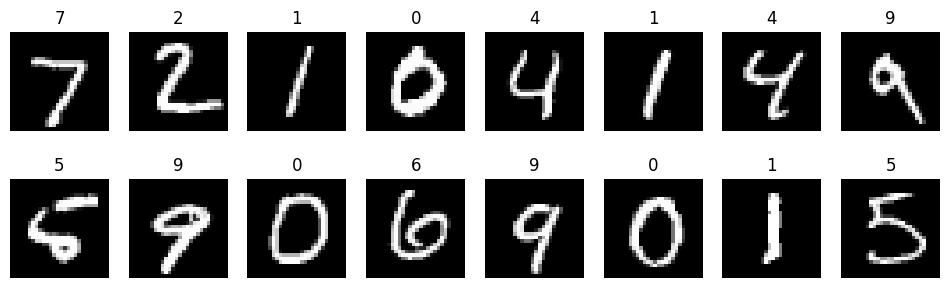

In [2]:
MEAN, STD = 0.1307, 0.3081
train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.MNIST("data", train=True, download=True, transform=train_tf)
val_base   = datasets.MNIST("data", train=True, download=True, transform=test_tf)
test_set   = datasets.MNIST("data", train=False, download=True, transform=test_tf)

g = torch.Generator().manual_seed(42)
train_idx, val_idx = random_split(range(60000), [55000, 5000], generator=g)
train_set = torch.utils.data.Subset(full_train, train_idx.indices)
val_set   = torch.utils.data.Subset(val_base, val_idx.indices)

train_dl = DataLoader(train_set, batch_size=128, shuffle=True)
val_dl   = DataLoader(val_set, batch_size=256)
test_dl  = DataLoader(test_set, batch_size=256)

# look at some samples
fig, ax = plt.subplots(2, 8, figsize=(12, 3.5))
for i, a in enumerate(ax.flat):
    img, y = test_set[i]
    a.imshow(img.squeeze(), cmap="gray"); a.set_title(y); a.axis("off")
plt.show()

In [3]:
class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.25),                    # 28 -> 14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.25))                    # 14 -> 7
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.5), nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

model = DigitCNN().to(device)
print(sum(p.numel() for p in model.parameters()), "parameters")

468202 parameters


In [4]:
EPOCHS = 10
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_dl))

def evaluate(dl):
    model.eval(); loss = correct = n = 0
    with torch.no_grad():
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss += F.cross_entropy(out, y, reduction="sum").item()
            correct += (out.argmax(1) == y).sum().item(); n += len(y)
    return loss / n, correct / n

hist = {"tr_loss": [], "val_loss": [], "tr_acc": [], "val_acc": []}
for ep in range(EPOCHS):
    model.train(); tl = tc = n = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = model(x); loss = F.cross_entropy(out, y)
        loss.backward(); opt.step(); sched.step()
        tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
    vl, va = evaluate(val_dl)
    hist["tr_loss"].append(tl / n); hist["tr_acc"].append(tc / n)
    hist["val_loss"].append(vl);    hist["val_acc"].append(va)
    print(f"Epoch {ep+1:2d}/{EPOCHS} | train loss {tl/n:.4f} acc {tc/n:.4f} | val loss {vl:.4f} acc {va:.4f}")

Epoch  1/10 | train loss 0.7667 acc 0.7501 | val loss 0.0784 acc 0.9770
Epoch  2/10 | train loss 0.2032 acc 0.9395 | val loss 0.0571 acc 0.9840
Epoch  3/10 | train loss 0.1671 acc 0.9499 | val loss 0.0452 acc 0.9868
Epoch  4/10 | train loss 0.1318 acc 0.9623 | val loss 0.0462 acc 0.9874
Epoch  5/10 | train loss 0.1000 acc 0.9711 | val loss 0.0408 acc 0.9868
Epoch  6/10 | train loss 0.0834 acc 0.9760 | val loss 0.0303 acc 0.9904
Epoch  7/10 | train loss 0.0698 acc 0.9799 | val loss 0.0258 acc 0.9922
Epoch  8/10 | train loss 0.0578 acc 0.9835 | val loss 0.0214 acc 0.9940
Epoch  9/10 | train loss 0.0506 acc 0.9860 | val loss 0.0205 acc 0.9938
Epoch 10/10 | train loss 0.0472 acc 0.9865 | val loss 0.0211 acc 0.9942


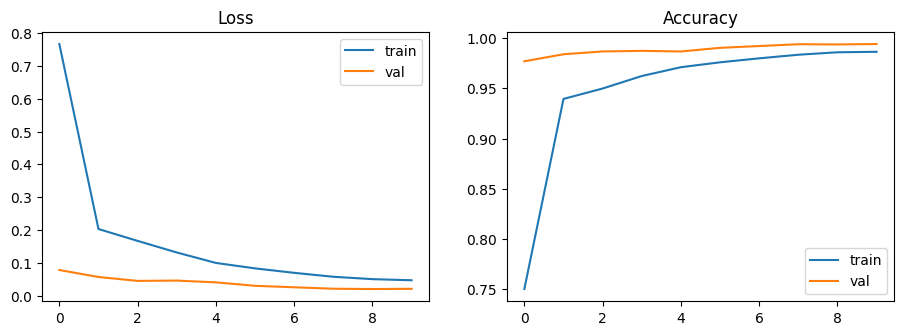

Test accuracy: 99.59%


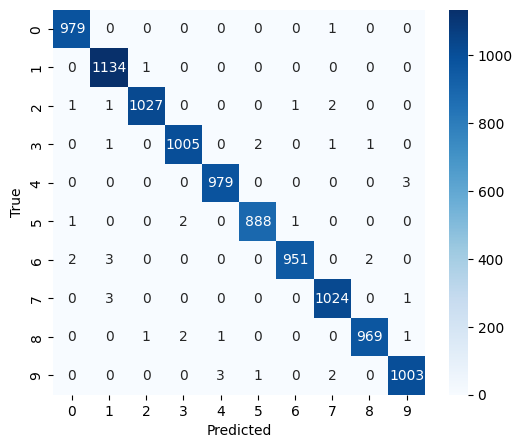

              precision    recall  f1-score   support

           0     0.9959    0.9990    0.9975       980
           1     0.9930    0.9991    0.9960      1135
           2     0.9981    0.9952    0.9966      1032
           3     0.9960    0.9950    0.9955      1010
           4     0.9959    0.9969    0.9964       982
           5     0.9966    0.9955    0.9961       892
           6     0.9979    0.9927    0.9953       958
           7     0.9942    0.9961    0.9951      1028
           8     0.9969    0.9949    0.9959       974
           9     0.9950    0.9941    0.9945      1009

    accuracy                         0.9959     10000
   macro avg     0.9960    0.9958    0.9959     10000
weighted avg     0.9959    0.9959    0.9959     10000



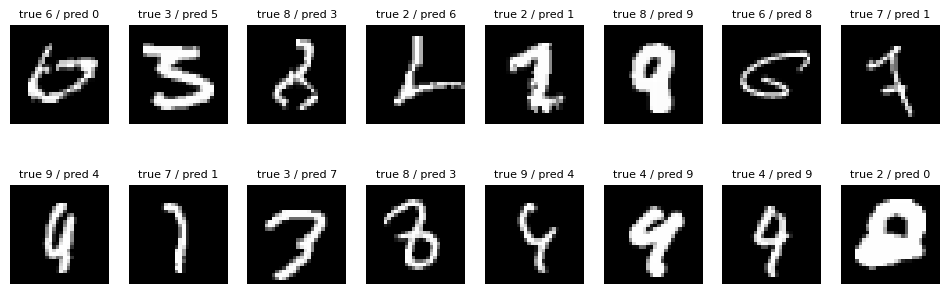

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist["tr_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(hist["tr_acc"], label="train");  ax[1].plot(hist["val_acc"], label="val");  ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

test_loss, test_acc = evaluate(test_dl)
print(f"Test accuracy: {test_acc*100:.2f}%")   # expect ~99.4-99.6%

# confusion matrix + per-class report
preds, labels, wrong = [], [], []
model.eval()
with torch.no_grad():
    for x, y in test_dl:
        p = model(x.to(device)).argmax(1).cpu()
        preds += p.tolist(); labels += y.tolist()
        for xi, yi, pi in zip(x, y, p):
            if yi != pi: wrong.append((xi, yi.item(), pi.item()))
plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(labels, preds), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()
print(classification_report(labels, preds, digits=4))

# misclassified examples
fig, ax = plt.subplots(2, 8, figsize=(12, 3.8))
for a, (img, t, p) in zip(ax.flat, wrong[:16]):
    a.imshow(img.squeeze(), cmap="gray"); a.set_title(f"true {t} / pred {p}", fontsize=8); a.axis("off")
plt.show()

In [6]:
torch.save(model.state_dict(), "mnist_cnn.pt")

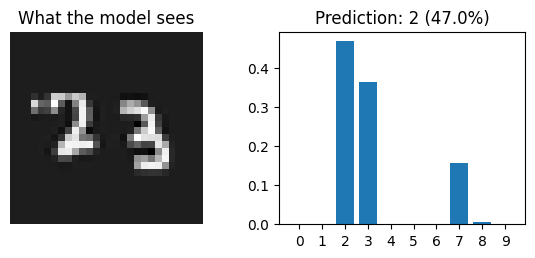

In [7]:
from PIL import Image
import io, base64
from scipy import ndimage
from IPython.display import HTML, JSON, display

def preprocess(pil_img):
    """White digit on black background -> normalized 1x1x28x28 tensor, MNIST style."""
    a = np.array(pil_img.convert("L"), dtype=np.float32)
    ys, xs = np.where(a > 20)
    if len(ys) == 0: return None
    a = a[ys.min():ys.max()+1, xs.min():xs.max()+1]          # crop to bounding box
    h, w = a.shape; s = 20.0 / max(h, w)                      # fit in 20x20
    a = np.array(Image.fromarray(a).resize((max(1,round(w*s)), max(1,round(h*s))), Image.LANCZOS))
    canvas = np.zeros((28, 28), dtype=np.float32)
    r, c = (28 - a.shape[0]) // 2, (28 - a.shape[1]) // 2
    canvas[r:r+a.shape[0], c:c+a.shape[1]] = a
    cy, cx = ndimage.center_of_mass(canvas)                   # centre by mass
    canvas = ndimage.shift(canvas, (14 - cy, 14 - cx), order=1)
    t = torch.tensor(canvas / 255.0).unsqueeze(0).unsqueeze(0)
    return (t - MEAN) / STD

def predict(pil_img, show=True):
    x = preprocess(pil_img)
    if x is None: return None
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(x.to(device)), 1)[0].cpu().numpy()
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(7, 2.5))
        ax[0].imshow(x.squeeze() * STD + MEAN, cmap="gray"); ax[0].axis("off"); ax[0].set_title("What the model sees")
        ax[1].bar(range(10), probs); ax[1].set_xticks(range(10)); ax[1].set_title(f"Prediction: {probs.argmax()} ({probs.max()*100:.1f}%)")
        plt.show()
    return probs

# ---- Colab canvas ----
from google.colab import output
def _cb(data_url):
    img = Image.open(io.BytesIO(base64.b64decode(data_url.split(",")[1])))
    predict(img)
    return JSON({"ok": True})
output.register_callback("predict_digit", _cb)

display(HTML("""
<canvas id="c" width="280" height="280" style="background:#000;border:2px solid #888;touch-action:none"></canvas><br>
<button id="p">Predict</button> <button id="x">Clear</button>
<script>
const c=document.getElementById('c'), g=c.getContext('2d'); let d=false;
g.lineWidth=18; g.lineCap='round'; g.strokeStyle='#fff';
c.onpointerdown=e=>{d=true;g.beginPath();g.moveTo(e.offsetX,e.offsetY)};
c.onpointermove=e=>{if(d){g.lineTo(e.offsetX,e.offsetY);g.stroke()}};
c.onpointerup=()=>d=false;
document.getElementById('x').onclick=()=>{g.clearRect(0,0,280,280);g.fillStyle='#000';g.fillRect(0,0,280,280)};
document.getElementById('p').onclick=()=>google.colab.kernel.invokeFunction('predict_digit',[c.toDataURL('image/png')],{});
</script>"""))